# This script does the 3D PFM switching spectroscopy
### @utor: Marti Checa, Fall 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import sawtooth
import time
from sys import exit
from scipy import signal
#from nifpga import Session
import time
import pylab as pl
from IPython import display
import win32com.client  
import os
from joblib import Parallel, delayed
import pythoncom
import sidpy as sid
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
import warnings
warnings.filterwarnings('ignore')

import h5py
import pyNSID

from scipy.special import erf

# import acquition.py
from Acquisition_v0_2 import Acquisition   # include the Acquistion_v0.py in the same directory

## Start executable of PyScanner and get control over it and over IGOR

In [2]:
#exe_path = r'C:\Users\3un\Documents\Hedgehogs\BEPyAE 051123 01\\BEPyAE.exe'
#exe_path = r'C:\Users\Asylum User\Desktop\FPGA Programs\Marti Checa\Spirals for Pascal\BEPyAE 051123 01\\BEPyAE.exe'
#exe_path = r'C:\Users\Asylum User\Desktop\STAFF Software\MartiAE\BEPyAE 051123 01\\BEPyAE.exe'
exe_path = r'C:\Users\Asylum User\Desktop\CNMS STAFF Software\BEPyAE 060523 01\BEPyAE.exe'
os.startfile(exe_path)
time.sleep(1)

In [3]:
labview = win32com.client.Dispatch("BEPyAE.Application")
#slash is critical here: double slash, tilt to left
#VI = labview.getvireference(r'C:\\Users\\3un\\Documents\\Hedgehogs\\BEPyAE 051123 01\\BEPyAE.exe\\FPGA PyScanner\\FPGA_PyScanner_01.vi')
VI = labview.getvireference(r'C:\Users\Asylum User\Desktop\CNMS STAFF Software\BEPyAE 060523 01\\BEPyAE.exe\\FPGA PyScanner\\FPGA_PyScanner_01.vi') 
#VI = labview.getvireference(r'C:\Users\Asylum User\Desktop\FPGA Programs\Marti Checa\Spirals for Pascal\BEPyAE 051123 01\\BEPyAE.exe\\FPGA PyScanner\\FPGA_PyScanner_01.vi') 

In [4]:
client = "IgorPro.Application"
igor = win32com.client.Dispatch(client)

## Imported funtions

In [72]:
#Necesarry functions

def triangular_onoff_pattern(cycle_amplitude, cycle_phase_shift, cycle_num,
                             steps_per_cycle, points_per_step,
                             cycle_fraction_initial, cycle_fraction_final):
    """
    Generate a triangular ON/OFF waveform segment between two fractional cycle positions.

    Parameters
    ----------
    cycle_amplitude : float
        Peak amplitude of the triangular waveform.
    cycle_phase_shift : float
        Phase shift (in units of cycles, e.g., 0.5 = 180° shift).
    cycle_num : int
        Number of times to repeat the waveform segment.
    steps_per_cycle : int
        Number of discrete voltage steps per full cycle.
    points_per_step : int
        Number of points per voltage step.
    cycle_fraction_initial : float
        Starting fractional position within one cycle (0 = start, 1 = end).
    cycle_fraction_final : float
        Ending fractional position within one cycle (0 = start, 1 = end).

    Returns
    -------
    step_time : np.ndarray
        Time or step index array.
    pulse_triangular : np.ndarray
        Triangular waveform with ON/OFF pattern between the specified fractions.
    tri_waveform : np.ndarray
        Full (unmasked) triangular waveform for reference.
    """

    # --- Time axis ---
    step = np.linspace(0, 1, steps_per_cycle, endpoint=False)
    step = np.repeat(step, points_per_step)

    # --- Bipolar triangular waveform ---
    tri_waveform = cycle_amplitude * sawtooth(
        2*np.pi*step + np.pi/2 + np.pi*cycle_phase_shift*2,
        width=0.5
    )

    # --- ON/OFF pulse pattern ---
    pulse_pattern = np.repeat([1, 0], points_per_step//2)
    pulse_pattern = np.tile(pulse_pattern, steps_per_cycle)

    pulse_triangular = tri_waveform * pulse_pattern

    # --- Select only the segment between the initial and final fractions ---
    n_total = len(pulse_triangular)
    i_start = int(np.clip(cycle_fraction_initial * n_total, 0, n_total))
    i_end   = int(np.clip(cycle_fraction_final   * n_total, 0, n_total))

    segment = pulse_triangular[i_start:i_end]

    # --- Repeat the segment for the number of cycles ---
    pulse_triangular = np.tile(segment, cycle_num)
    step_time = np.arange(len(pulse_triangular))

    return step_time, pulse_triangular, tri_waveform

def save_data(filename, location, bias_step, Gain_lockin=1e-3 , Gains_QPDI=15.95, Gains_Phase=18, amp_pha=True):
    
    #Generate a 0 DC bias vector and add it to AO2:
    ZeroDC_vec = np.linspace(0, 0, num = N_points,dtype=float)
    VI.setcontrolvalue('UI_AO2_V',ZeroDC_vec.tolist())
    
    VI.setcontrolvalue('do_scan_update', 1) #need to tell PyScanner to update parameters internally 
    updating = True
    while (updating==True):
        updating = VI.getcontrolvalue('do_scan_update')
    #Performing scan  
    VI.setcontrolvalue('do_scan', 1)# do scan
    #keep checking if scan is complete
    scanning = True
    while (scanning==True):
        scanning = VI.getcontrolvalue('do_scan')
        
    #Save left data
    ai = np.asarray(VI.getcontrolvalue('AI_vs_time'))
   
    if amp_pha == True:
        #Average the signal and jut save the average amplitude 
        ai0_mean = np.mean(ai[0,:])*Gains_QPDI*Gain_lockin
        #Average the signal and jut save the average phase
        ai1_mean = np.mean(ai[1,:])*Gains_Phase
    else:
        ai0_mean = np.mean(ai[0,:])*Gain_lockin*Gains_QPDI
        ai1_mean = np.mean(ai[1,:])*Gain_lockin*Gains_QPDI
        
        #We now calcuklate amp and phase
        ai0_mean = np.hypot(ai0_mean, ai1_mean)  
        ai1_mean = np.degrees(np.arctan2(ai1_mean, ai0_mean))  
        
    filename_=filename+location
    
    # Choose mode: 'w' the first time, 'a' after that
    mode = 'a' if os.path.exists(filename_) else 'w'
    with open(filename_, mode) as f:
        np.savetxt(f, np.array([[bias_step, ai0_mean, ai1_mean]]), fmt="%.6f")
    
    return

def move_laser_and_measure(N_points, filename, bias_step, delta_x, delta_y, time_sleep=0.5, amp_pha=True):
    
    #Move laser spot to left
    igor.Execute('DoScanFunc("StopEngageButton")')
    
    approach_coordinate(igor, T, [0.1,0.7], limit = 70, reps = 3)
    #for j in range(ny):    
        #igor.Execute('DoLDMove('+ '0' + ',' + str(step_delta_y) +')')
        #time.sleep(time_sleep)
        
    igor.Execute('ZeroPD("")')
    time.sleep(time_sleep)
    igor.Execute('ARVideoButtonFunc("ARVCapture")')
    igor.Execute('SimpleEngageMe("")')
    #Save data left
    save_data(filename=filename, location='_Left.txt',bias_step = bias_step, amp_pha=amp_pha)
    
    #Move laser spot to right
    igor.Execute('DoScanFunc("StopEngageButton")')
    approach_coordinate(igor, T, [0.1,-0.65], limit = 70, reps = 3)
    #for j in range(ny): 
        #igor.Execute('DoLDMove('+ '0' + ',-' + str(step_delta_y) +')')
        #time.sleep(time_sleep)
        #igor.Execute('DoLDMove('+ '0' + ',-' + str(step_delta_y) +')')
        #time.sleep(time_sleep)
        
    igor.Execute('ZeroPD("")')
    time.sleep(time_sleep)
    igor.Execute('ARVideoButtonFunc("ARVCapture")')
    igor.Execute('SimpleEngageMe("")')
    #Save right data
    save_data(filename=filename, location='_Right.txt',bias_step = bias_step, amp_pha=amp_pha)
    
    #Move laser spot to past
    igor.Execute('DoScanFunc("StopEngageButton")')
    approach_coordinate(igor, T, [0.9,0], limit = 70, reps = 3)
    #for j in range(ny):
        #igor.Execute('DoLDMove('+ '0' + ',' + str(step_delta_y) +')')
        #time.sleep(time_sleep)
    #for j in range(nx): 
        #igor.Execute('DoLDMove('+ str(step_delta_x) + ',' + '0' +')')
        #time.sleep(time_sleep)
        
    igor.Execute('ZeroPD("")')
    time.sleep(time_sleep)
    igor.Execute('ARVideoButtonFunc("ARVCapture")')
    igor.Execute('SimpleEngageMe("")')
    #Save past data
    save_data(filename=filename, location='_Past.txt',bias_step = bias_step, amp_pha=amp_pha)
    
    #Move laser spot to before
    igor.Execute('DoScanFunc("StopEngageButton")')
    approach_coordinate(igor, T, [-0.1,0], limit = 70, reps = 3)
    #for j in range(nx): 
        #igor.Execute('DoLDMove(-'+ str(step_delta_x) + ',' + '0' +')')
        #time.sleep(time_sleep)
        #igor.Execute('DoLDMove(-'+ str(step_delta_x) + ',' + '0' +')')
        #time.sleep(time_sleep)
        
    igor.Execute('ZeroPD("")')
    time.sleep(time_sleep)
    igor.Execute('ARVideoButtonFunc("ARVCapture")')
    igor.Execute('SimpleEngageMe("")')
    #Save before data
    save_data(filename=filename, location='_Before.txt',bias_step = bias_step, amp_pha=amp_pha)
    
    #Move back to center
    igor.Execute('DoScanFunc("StopEngageButton")')
    approach_coordinate(igor, T, [0,0], limit = 70, reps = 3)
    
    #for j in range(nx): 
        #igor.Execute('DoLDMove('+ str(step_delta_x) + ',' + '0' +')')
        #time.sleep(time_sleep)
    igor.Execute('ARVideoButtonFunc("ARVCapture")')
    time.sleep(time_sleep)
        
    return

## Parameters

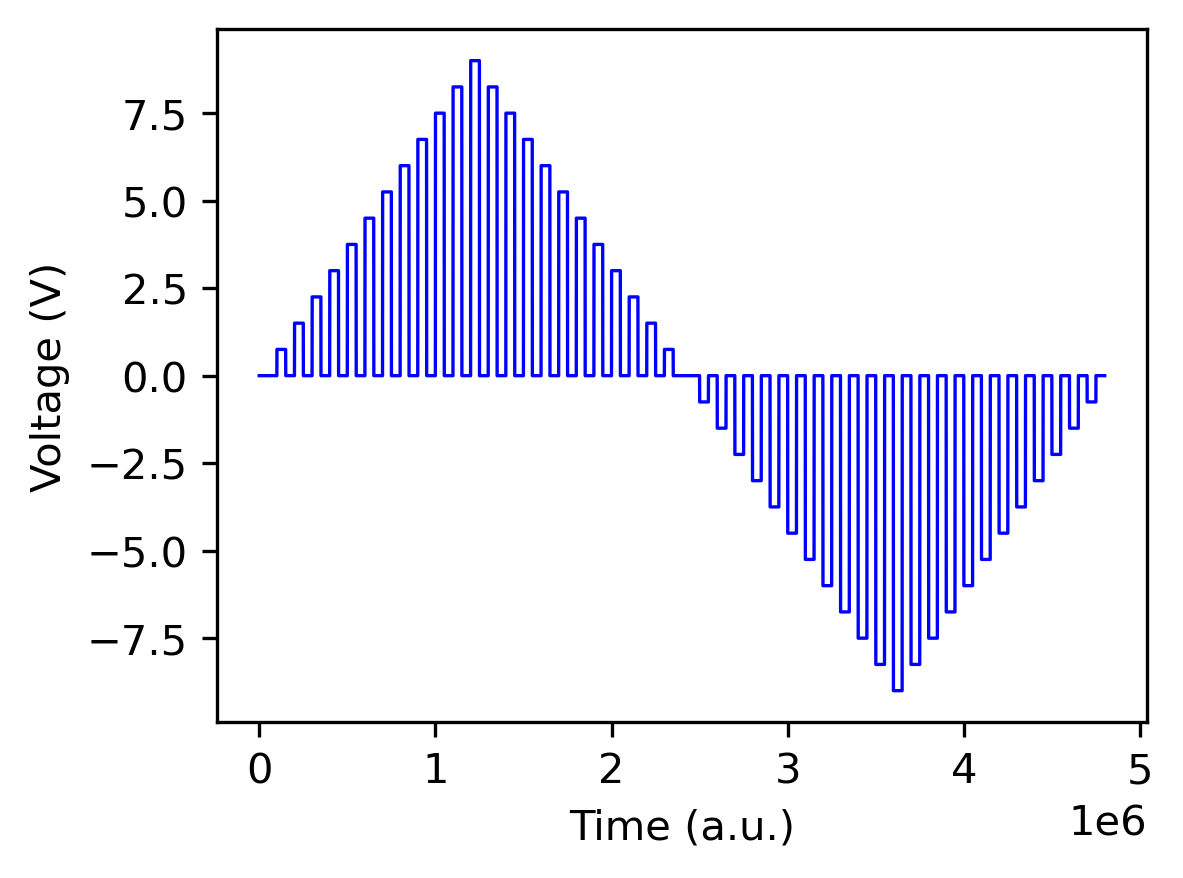

In [57]:
#Define the parameters of the SS wave:
cycle_amplitude=9
cycle_phase_shift=0
cycle_num=1
steps_per_cycle= 48
points_per_step=20 #needs to be an even number

## Parameters laser movement
delta_x=3
delta_y=5

step_delta_x=1
step_delta_y=1

nx=int(delta_x/step_delta_x)
ny=int(delta_y/step_delta_y)

#Experimental Parameters
r0=(2/3)
L= 225e-6
x0=14e-6
Gx=1
Gy=1

#Parameters FPGA
IO_rate = float(1E6) # IO rate of FPGA [samples/s] - not this could be 10 or 100 times slower
duration = 0.1 # time to scan one line trace+retrace [Hz]
N_points = int(duration*IO_rate) #number of data points defining output waveforms

#Savings
path_save= r'C:\Users\Asylum User\Desktop\STAFF Software\MartiAE\3D Loops\data_save\\'
filename_base= 'OFF_Loops_ExternalLockin_v5_ONWrittenArea'

ts, wv, _ = triangular_onoff_pattern(cycle_amplitude = cycle_amplitude, cycle_phase_shift = cycle_phase_shift,
                                  cycle_num = 1, steps_per_cycle = steps_per_cycle, points_per_step = N_points,
                                  cycle_fraction_initial=0,
                                  cycle_fraction_final=1)

plt.figure(figsize= (4,3), dpi = 300)
plt.plot(ts, wv, c = 'blue', linewidth = 0.8)
plt.xlabel("Time (a.u.)")
plt.ylabel("Voltage (V)")
plt.show()

## Test laser movement dimensions

In [12]:
igor.Execute('DoScanFunc("StopEngageButton")')

delta_x=7.5
delta_y=12

step_delta_x=2.5
step_delta_y=3

nx=int(delta_x/step_delta_x)
ny=int(delta_y/step_delta_y)

for i in range(3):

    for j in range(ny):    
        igor.Execute('DoLDMove('+ '0' + ',' + str(step_delta_y) +')')
        time.sleep(0.35)

    for j in range(ny): 
        igor.Execute('DoLDMove('+ '0' + ',-' + str(step_delta_y) +')')
        time.sleep(0.35)
        igor.Execute('DoLDMove('+ '0' + ',-' + str(step_delta_y) +')')
        time.sleep(0.35)
        
    for j in range(ny):
        igor.Execute('DoLDMove('+ '0' + ',' + str(step_delta_y) +')')
        time.sleep(0.35)

    for j in range(nx): 
        igor.Execute('DoLDMove('+ str(step_delta_x) + ',' + '0' +')')
        time.sleep(0.35)

    for j in range(nx): 
        igor.Execute('DoLDMove(-'+ str(step_delta_x) + ',' + '0' +')')
        time.sleep(0.35)
        igor.Execute('DoLDMove(-'+ str(step_delta_x) + ',' + '0' +')')
        time.sleep(0.35)
        
    for j in range(nx): 
        igor.Execute('DoLDMove('+ str(step_delta_x) + ',' + '0' +')')
        time.sleep(0.35)

## Launch individual 3D PFM Loop

In [6]:
def make_3D_Loop(path_save,filename_base, plotting=True, cycle_num=1):
    
    VI.setcontrolvalue('scan_type', 0)#change to User defined scan

    for j in range(cycle_num):
    
        print('We start the '+ str(j+1) + ' cycle of the loop')
    
        for i in range(1,steps_per_cycle+1):

            ts, wv, _ = triangular_onoff_pattern(cycle_amplitude = cycle_amplitude, cycle_phase_shift = cycle_phase_shift,
                                  cycle_num = cycle_num, steps_per_cycle = steps_per_cycle, points_per_step = N_points,
                                  cycle_fraction_initial=(i-1)/((steps_per_cycle)),
                                  cycle_fraction_final=i/((steps_per_cycle)))
   
            #We plot 1 cycle
            if plotting==True:
                plt.figure(figsize= (4,3), dpi = 300)
                plt.plot(ts, wv, c = 'blue', linewidth = 0.8)
                plt.xlabel("Time (a.u.)")
                plt.ylabel("Voltage (V)")
                plt.xlim([0, N_points])
                plt.ylim([-cycle_amplitude*1.1,cycle_amplitude*1.1])
                plt.show()
    
            #we Charge the Bias to the output
            #V_vec= wv*0.1 #If using HV holder
            V_vec= wv
            AO_zeros_vec= np.zeros_like(V_vec)

            VI.setcontrolvalue('UI_AO0_V',AO_zeros_vec.tolist())
            VI.setcontrolvalue('UI_AO1_V',AO_zeros_vec.tolist())
            VI.setcontrolvalue('UI_AO2_V',V_vec.tolist())
            VI.setcontrolvalue('UI_AO3_V',AO_zeros_vec.tolist())
            #update the scan parameters and wait until finished
            VI.setcontrolvalue('do_scan_update', 1)
            updating = True
            while (updating==True):
                updating = VI.getcontrolvalue('do_scan_update')
        
            #We engage
            igor.Execute('SimpleEngageMe("")')
        
            #Performing scan  
            VI.setcontrolvalue('do_scan', 1)# do scan
            #keep checking if scan is complete
            scanning = True
            while (scanning==True):
                scanning = VI.getcontrolvalue('do_scan')
        
            print('Moving the laser and measuring at spot '+ str(i)+' of:' + str(steps_per_cycle+1))
            print(path_save+filename_base)
            move_laser_and_measure(N_points=N_points, filename=path_save+filename_base, 
                           bias_step=wv[0], 
                           delta_x=delta_x, delta_y=delta_y, amp_pha=True)

            #if i == int(steps_per_cycle/2) or i == int(1) :
                #print('Manual readjust of Laser position')
                #input("\nPlease realign manually, then press ENTER to continue")
        
    return

#make_3D_Loop(path_save=path_save,filename_base=filename_base, plotting=True)

## Ploting the individual loops at each tip position

FileNotFoundError: C:\Users\Asylum User\Desktop\STAFF Software\MartiAE\3D Loops\data_save\\OFF_Loops_ExternalLockin_v5_ONWrittenArea_Left.txt not found.

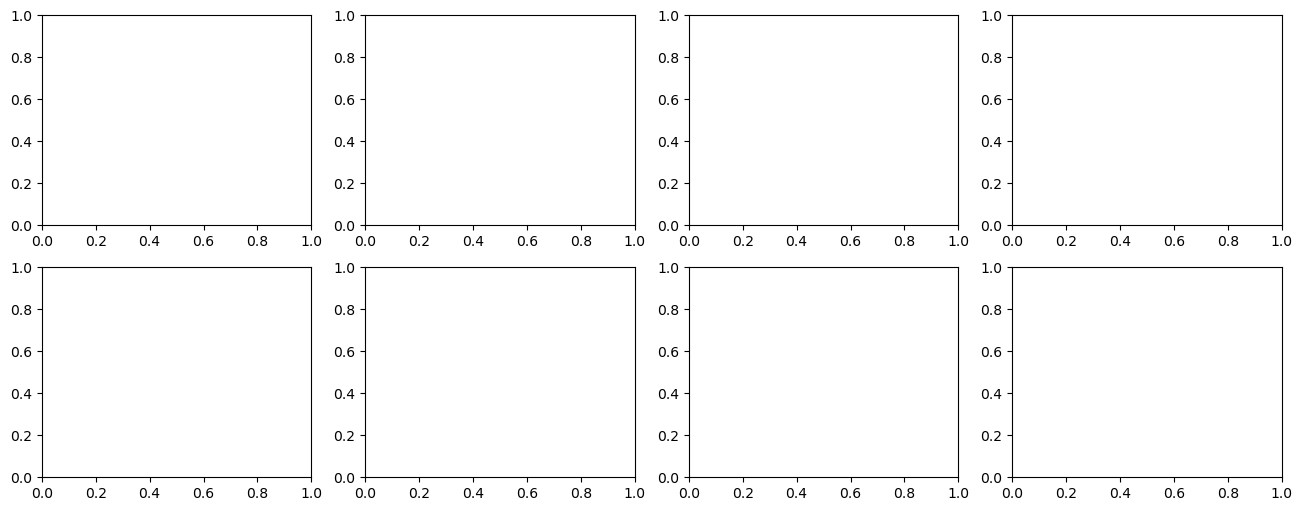

In [10]:
# ---- Input filenames ----
filenames = [
    path_save+filename_base+'_Left.txt',
    path_save+filename_base+'_Right.txt',
    path_save+filename_base+'_Past.txt',
    path_save+filename_base+'_Before.txt',
]

# ---- Create 2x4 subplot grid ----
fig, axs = plt.subplots(2, 4, figsize=(16, 6), sharex=False, sharey=False)

for i, fname in enumerate(filenames):
    data = np.loadtxt(fname)
    bias = data[:, 0]
    amplitude = data[:, 1]
    phase = data[:, 2]

    # Extract short title from filename (last word before underscore)
    base = os.path.basename(fname)
    short_title = base.split("_")[-1].split(".")[0]

    # Top row: Bias vs Amplitude
    axs[0, i].plot(bias, amplitude,'-o', color='tab:blue')
    axs[0, i].set_title(short_title)
    axs[0, i].set_xlabel("Bias")
    axs[0, i].set_ylabel("Amplitude")
    axs[0, i].grid(True)

    # Bottom row: Bias vs Phase
    axs[1, i].plot(bias, phase, '-o', color='tab:orange')
    axs[1, i].set_title(short_title)
    axs[1, i].set_xlabel("Bias")
    axs[1, i].set_ylabel("Phase")
    axs[1, i].grid(True)

plt.tight_layout()
plt.show()

## Ploting the individual loops in eaxh physical dimension

In [11]:
# ---------- INPUT ----------
# Provide your files in any order; we map names to roles (y+ = Left, y- = Right, x+ = Past, x- = Before)
files = {
    "Left":   path_save + filename_base + "_Left.txt",    # y+
    "Right":  path_save + filename_base + "_Right.txt",   # y-
    "Past":   path_save + filename_base + "_Past.txt",    # x+
    "Before": path_save + filename_base + "_Before.txt",  # x-
}

# Parameters
ASSUME_PHASE_DEGREES = True
USE_WEIGHTED = False
L, h, dx, dy, r0 = 225e-6, 12e-6, 14e-6, 14e-6, 2/3
VAC = 1.0
USE_INPHASE = True

# ---------- HELPERS ----------
def compute_phasor(ampl, phase, assume_degrees=True):
    """Return A * exp(i*phi); auto-detect radians if phase values small."""
    if assume_degrees and np.nanmax(np.abs(phase)) < 7:  # looks like radians
        assume_degrees = False
    phi = np.deg2rad(phase) if assume_degrees else phase
    return ampl * np.exp(1j * phi)

def estimate_phi_inst(z_list):
    """Angle of the global mean phasor across all samples and channels."""
    vals = np.concatenate([z[np.isfinite(z)] for z in z_list]) if z_list else np.array([1+0j])
    m = np.mean(vals) if vals.size else 1+0j
    return float(np.angle(m)) if np.abs(m) != 0 else 0.0

def rotate_phase(z, phi_inst=0.0):
    return z * np.exp(-1j * phi_inst)

def vector_components_simple(wx_p, wx_m, wy_p, wy_m):
    ux = 0.5 * (wx_p - wx_m)
    uy = 0.5 * (wy_p - wy_m)
    uz_x = 0.5 * (wx_p + wx_m)
    uz_y = 0.5 * (wy_p + wy_m)
    uz = 0.5 * (uz_x + uz_y)
    return ux, uy, uz

def vector_components_weighted(wx_p, wx_m, wy_p, wy_m, L, x_plus, x_minus, y_plus, y_minus, h, r0=2/3):
    Gx = (np.abs(x_plus) / h) if h else 1.0
    Gy = (np.abs(y_plus) / h) if h else 1.0
    ux = ((r0*L - x_minus) * wx_p - (r0*L + x_plus) * wx_m) / (2 * r0 * L * Gx)
    uy = (wy_p - wy_m) / (2 * Gy)
    uz_from_x = 0.5 * (wx_p + wx_m)
    uz_from_y = 0.5 * (wy_p + wy_m)
    uz = 0.5 * (uz_from_x + uz_from_y)
    return ux, uy, uz

def compute_deff(u_complex, Vac=None, use_inphase=True):
    if use_inphase:
        signed = np.real(u_complex)
        return signed if (Vac is None or Vac == 0) else (signed / Vac)
    else:
        amp = np.abs(u_complex)
        return amp if (Vac is None or Vac == 0) else (amp / Vac)

def _load_xyphi(fname):
    """Expect 3 columns per row: [bias, amplitude, phase]."""
    arr = np.loadtxt(fname)
    if arr.ndim == 1:
        arr = arr.reshape(1, -1)
    if arr.shape[1] < 3:
        raise ValueError(f"{fname} must have at least 3 columns: bias amplitude phase")
    return arr[:,0], arr[:,1], arr[:,2]

# ---------- LOAD FILES ----------
bias_L, A_L, P_L = _load_xyphi(files["Left"])
bias_R, A_R, P_R = _load_xyphi(files["Right"])
bias_P, A_P, P_P = _load_xyphi(files["Past"])
bias_B, A_B, P_B = _load_xyphi(files["Before"])

# Sanity check: all bias vectors should match
bias = bias_L
if not (np.allclose(bias_R, bias) and np.allclose(bias_P, bias) and np.allclose(bias_B, bias)):
    raise ValueError("Bias vectors are not identical across files!")

# ---------- PHASORS & INSTRUMENT PHASE ----------
w_L = compute_phasor(A_L, P_L, assume_degrees=ASSUME_PHASE_DEGREES)  # y+
w_R = compute_phasor(A_R, P_R, assume_degrees=ASSUME_PHASE_DEGREES)  # y-
w_P = compute_phasor(A_P, P_P, assume_degrees=ASSUME_PHASE_DEGREES)  # x+
w_B = compute_phasor(A_B, P_B, assume_degrees=ASSUME_PHASE_DEGREES)  # x-

phi_inst = estimate_phi_inst([w_L, w_R, w_P, w_B])
wL = rotate_phase(w_L, phi_inst)  # y+
wR = rotate_phase(w_R, phi_inst)  # y-
wP = rotate_phase(w_P, phi_inst)  # x+
wB = rotate_phase(w_B, phi_inst)  # x-

# ---------- VECTOR RECONSTRUCTION ----------
if USE_WEIGHTED:
    ux_c, uy_c, uz_c = vector_components_weighted(
        wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR,
        L=L, x_plus=+dx, x_minus=-dx, y_plus=+dy, y_minus=-dy, h=h, r0=r0
    )
else:
    ux_c, uy_c, uz_c = vector_components_simple(
        wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR
    )

# ---------- OUTPUT ----------
ux_map = compute_deff(ux_c, Vac=VAC, use_inphase=USE_INPHASE)
uy_map = compute_deff(uy_c, Vac=VAC, use_inphase=USE_INPHASE)
uz_map = compute_deff(uz_c, Vac=VAC, use_inphase=USE_INPHASE)

print(f"Reconstruction done. Arrays length = {ux_map.size}")

# ---------- PLOTTING 3x3 SUBPLOTS ----------
fig, axs = plt.subplots(3, 3, figsize=(12, 9), sharex=True)
titles = ["Amplitude", "Phase", "Response (A·cosφ)"]
colors = ["tab:green", "tab:blue", "tab:red"]

def plot_row(ax_row, bias, A, P, u, title, color):
    phi_rad = np.deg2rad(P) if np.nanmax(np.abs(P)) > 2*np.pi else P
    response = A * np.cos(phi_rad)
    ax_row[0].plot(bias, A, color=color)
    ax_row[1].plot(bias, P, color=color)
    ax_row[2].plot(bias, response, color=color)
    for ax in ax_row:
        ax.grid(True)
    ax_row[0].set_ylabel(title, rotation=0, labelpad=30, fontsize=12)

# Compute amplitude and phase
A_ux, P_ux = np.abs(ux_c), np.angle(ux_c, deg=True)
A_uy, P_uy = np.abs(uy_c), np.angle(uy_c, deg=True)
A_uz, P_uz = np.abs(uz_c), np.angle(uz_c, deg=True)

# Fill 3×3 grid
plot_row(axs[0, :], bias, A_ux, P_ux, ux_c, "u_x", colors[0])
plot_row(axs[1, :], bias, A_uy, P_uy, uy_c, "u_y", colors[1])
plot_row(axs[2, :], bias, A_uz, P_uz, uz_c, "u_z", colors[2])

for j, label in enumerate(titles):
    axs[0, j].set_title(label, fontsize=12)
for ax in axs[-1, :]:
    ax.set_xlabel("Bias")

plt.tight_layout()
plt.show()

FileNotFoundError: C:\Users\Asylum User\Desktop\STAFF Software\MartiAE\3D Loops\data_save\\OFF_Loops_ExternalLockin_v5_ONWrittenArea_Left.txt not found.

## Launch a map of 3D PFM Loops

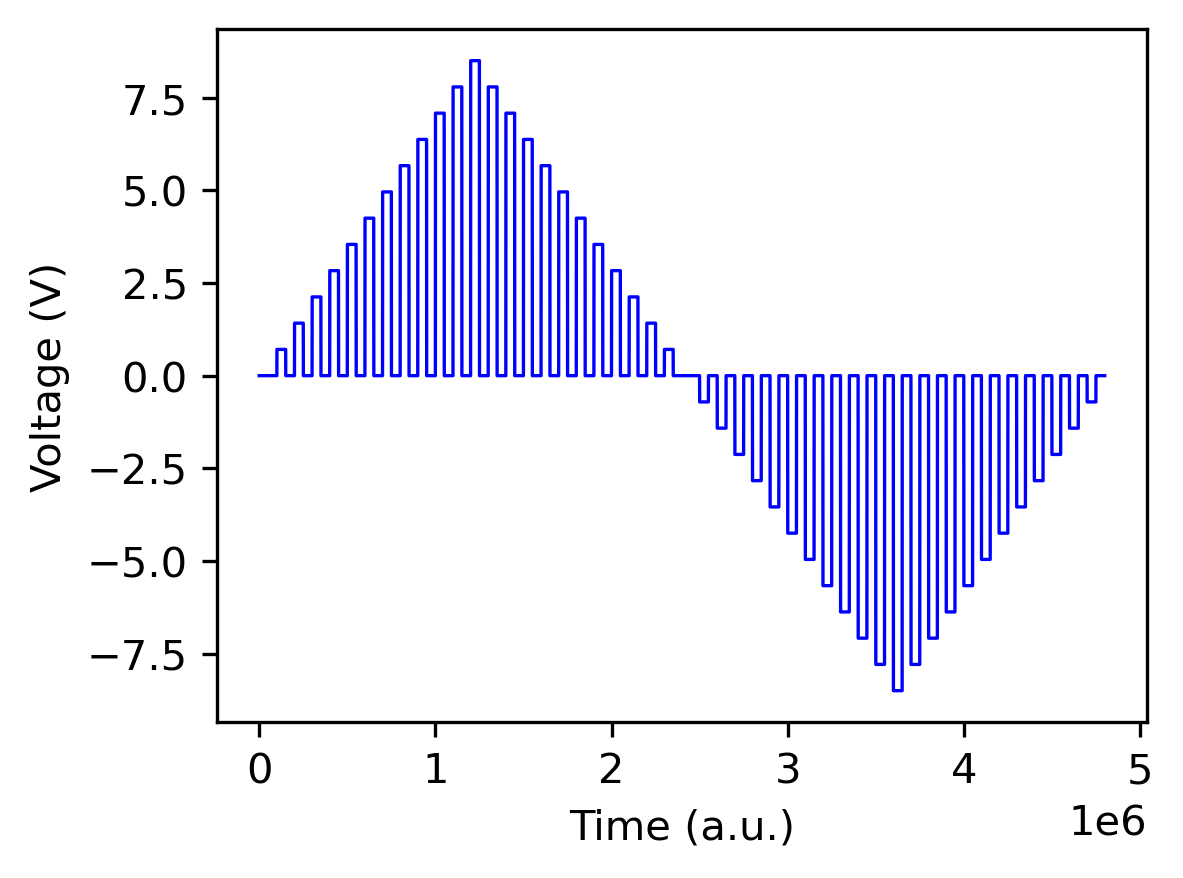

In [73]:
#Parameters
x_grid_positions=2
y_grid_positions=2

#Define the parameters of the SS wave:
cycle_amplitude=8.5
cycle_phase_shift=0
cycle_num=1
steps_per_cycle= 48
points_per_step=20 #needs to be an even number

## Parameters laser movement
delta_x=7.5
delta_y=12

step_delta_x=2.5
step_delta_y=3

nx=int(delta_x/step_delta_x)
ny=int(delta_y/step_delta_y)

#Experimental Parameters
r0=(2/3)
L= 225e-6
x0=14e-6
Gx=1
Gy=1

#Parameters FPGA
IO_rate = float(1E6) # IO rate of FPGA [samples/s] - not this could be 10 or 100 times slower
duration = 0.1 # time to scan one line trace+retrace [Hz]
N_points = int(duration*IO_rate) #number of data points defining output waveforms

#Set up the saving path
path_save = r'D:\User data\Marti\2025\Nov\18th\map4\\'
file_loc = r"D:\User data\Marti\2025\Nov\18th\map4"

base_filename = "calibr"

log_filename = "LogCalib"

ts, wv, _ = triangular_onoff_pattern(cycle_amplitude = cycle_amplitude, cycle_phase_shift = cycle_phase_shift,
                                  cycle_num = cycle_num, steps_per_cycle = steps_per_cycle, points_per_step = N_points,
                                  cycle_fraction_initial=0,
                                  cycle_fraction_final=1)

plt.figure(figsize= (4,3), dpi = 300)
plt.plot(ts, wv, c = 'blue', linewidth = 0.8)
plt.xlabel("Time (a.u.)")
plt.ylabel("Voltage (V)")
plt.show()

---
Capturing Image:
   Ocalibr10000.tif


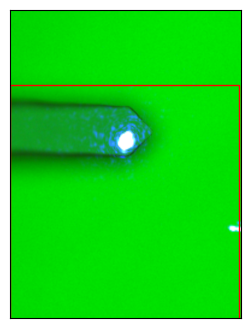

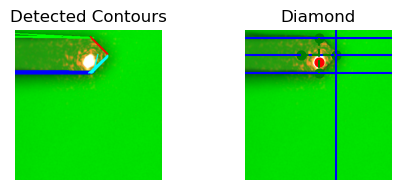

Calculated Position:
[0.004447018632321109, -0.3588846701944255]
Reasonable
---
Capturing Image:
   Ocalibr10001.tif


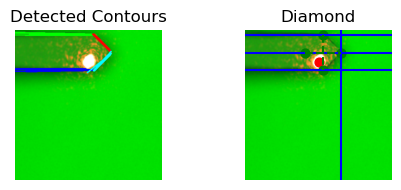

Calculated Position:
[-0.2366348416166284, -0.5141438313529665]
Reasonable
---
Capturing Image:
   Ocalibr10002.tif


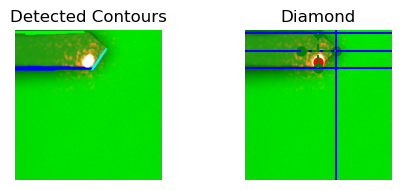

Calculated Position:
[-0.01563464351688748, -0.6139592106618108]
Reasonable
---
Capturing Image:
   Ocalibr10003.tif


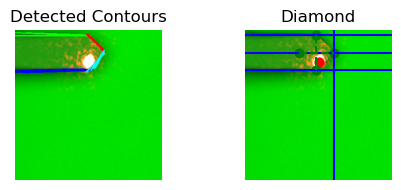

Calculated Position:
[0.12162511586091096, -0.5182082444071574]
Reasonable
---
Capturing Image:
   Ocalibr10004.tif


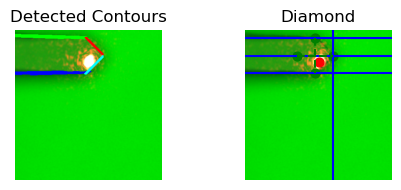

Calculated Position:
[0.2192582953806117, -0.3500474044719999]
Reasonable
---
Capturing Image:
   Ocalibr10005.tif


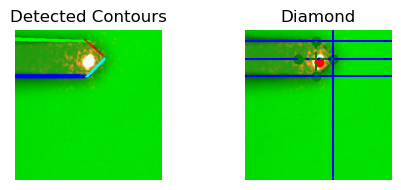

Calculated Position:
[0.15917525609863947, -0.1752968825075032]
Reasonable
---
Capturing Image:
   Ocalibr10006.tif


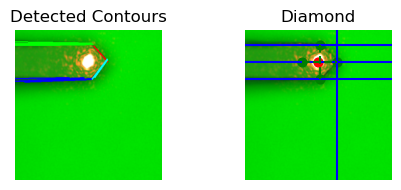

Calculated Position:
[-0.08943388908065697, 0.019436905498184776]
Reasonable
---
Capturing Image:
   Ocalibr10007.tif


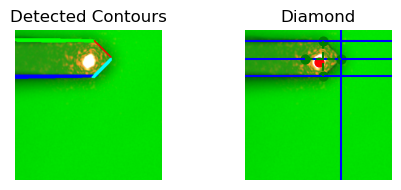

Calculated Position:
[-0.2487030113323484, -0.1725877870456185]
Reasonable
---
Capturing Image:
   Ocalibr10008.tif


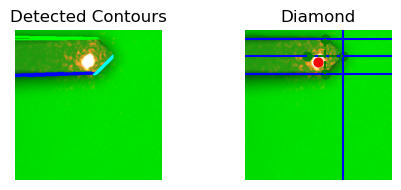

Calculated Position:
[-0.3943678615410391, -0.2952832102969458]
Reasonable
---
Capturing Image:
   Ocalibr10009.tif


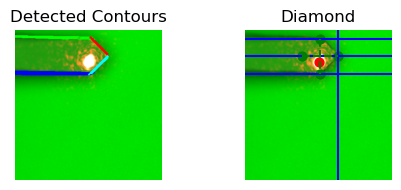

Calculated Position:
[-0.0591945669575743, -0.31380722172637276]
Reasonable
Affine Transform:
[[   88.96072555     2.23064587]
 [    3.73708297    93.9040003 ]
 [-2002.37035708   897.24087115]]
Valid Diamonds:
10 out of 10
We start the 1 cycle of the loop
Moving the laser and measuring at spot 1 of:49
D:\User data\Marti\2025\Nov\18th\map4\\(0,0)/OFF_Loops_Map_(0,0)
Moving the laser and measuring at spot 2 of:49
D:\User data\Marti\2025\Nov\18th\map4\\(0,0)/OFF_Loops_Map_(0,0)
Moving the laser and measuring at spot 3 of:49
D:\User data\Marti\2025\Nov\18th\map4\\(0,0)/OFF_Loops_Map_(0,0)
Moving the laser and measuring at spot 4 of:49
D:\User data\Marti\2025\Nov\18th\map4\\(0,0)/OFF_Loops_Map_(0,0)
Moving the laser and measuring at spot 5 of:49
D:\User data\Marti\2025\Nov\18th\map4\\(0,0)/OFF_Loops_Map_(0,0)
Moving the laser and measuring at spot 6 of:49
D:\User data\Marti\2025\Nov\18th\map4\\(0,0)/OFF_Loops_Map_(0,0)
Moving the laser and measuring at spot 7 of:49
D:\User data\Marti\2025\N

KeyboardInterrupt: 

In [76]:
os.chdir(r'C:\Users\Asylum User\Desktop\CNMS STAFF Software\Ralph\CleanCodes')

from ralph_tools import *

#We genenerate a GRID
igor.Execute('SpotGrid('+str(x_grid_positions)+','+str(y_grid_positions)+')')

n,m = 0,0 ##starting positions

#we start a loop
cont=0

for i in range(x_grid_positions):
    for j in range(y_grid_positions):
        
        cont=cont+1
        
        #skip until starting position
        if i < n or (i == n and j < m):  
            igor.Execute('PV("ForceSpotNumber",'+str(cont)+')')
            igor.Execute('GoToSpot()')
            
        else:
        
            T = calculate_asylum_coordinate_to_lab_coordinate_transform(igor,
                                                             file_loc = file_loc,
                                                             base_filename = base_filename+str(cont),
                                                             log_filename = log_filename+str(cont),
                                                             box=[0,125,380,452],
                                                             verbose=True)
            #We initialize at 0,0 laser spot position
            approach_coordinate(igor, T, [0,0], limit = 70, reps = 3)
        
            #go to next force curve
            igor.Execute('PV("ForceSpotNumber",'+str(cont)+')')
            #We move to the next spot
            igor.Execute('GoToSpot()')

            time.sleep(1)
        
            #Generate subfolder
            folder_name =os.path.join(path_save, '('+str(i)+','+str(j)+')/' )  # e.g., output_folder_0, output_folder_1, ...)
            os.makedirs(folder_name, exist_ok=True)  # creates the folder if it doesn't exist
        
            #Change the filename:
            filename_base= 'OFF_Loops_Map_('+str(i)+','+str(j)+')'
        
            #We make a tune
            make_3D_Loop(path_save=folder_name,filename_base=filename_base, plotting=False, cycle_num=cycle_num)
            time.sleep(1)

## Ploting all the loops at each laser position along all grid positions 

In [ ]:
# ---------- PARAMETERS ----------
path_save = path_save   # main directory containing all (i,j) folders
grid_i = range(x_grid_positions)                        # adjust to your grid
grid_j = range(y_grid_positions)

labels = ["Left", "Right", "Past", "Before"]
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']  # per direction color

# ---------- COLLECT ALL DATA ----------
data_all = {lbl: [] for lbl in labels}

for i in grid_i:
    for j in grid_j:
        folder_name = os.path.join(path_save, f"({i},{j})")
        filename_base = f"OFF_Loops_({i},{j})"

        if not os.path.isdir(folder_name):
            print(f"Skipping missing folder: {folder_name}")
            continue

        for lbl in labels:
            fname = os.path.join(folder_name, f"{filename_base}_{lbl}.txt")

            if not os.path.exists(fname):
                print(f"Missing file: {fname}")
                continue

            data = np.loadtxt(fname)
            if data.shape[1] < 3:
                print(f"Skipping malformed file: {fname}")
                continue

            bias = data[:, 0]
            amplitude = data[:, 1]
            phase = data[:, 2]

            data_all[lbl].append((bias, amplitude, phase))

print("✅ Finished collecting all loops.")

# ---------- PLOT ALL AND MEAN ----------
fig, axs = plt.subplots(2, 4, figsize=(16, 6), sharex=False, sharey=False)

for k, lbl in enumerate(labels):
    amp_list = []
    phase_list = []
    bias_ref = None

    # Plot all loops (gray)
    for (bias, amp, ph) in data_all[lbl]:
        axs[0, k].plot(bias, amp, color='lightgray', alpha=0.4)
        axs[1, k].plot(bias, ph, color='lightgray', alpha=0.4)

        if bias_ref is None:
            bias_ref = bias
        amp_list.append(amp)
        phase_list.append(ph)

    # Compute and plot mean
    if len(amp_list) > 0:
        amp_mean = np.mean(np.vstack(amp_list), axis=0)
        phase_mean = np.mean(np.vstack(phase_list), axis=0)

        axs[0, k].plot(bias_ref, amp_mean, color=colors[k], lw=2.5, label="Mean")
        axs[1, k].plot(bias_ref, phase_mean, color=colors[k], lw=2.5, label="Mean")

    # Labels and styling
    axs[0, k].set_title(lbl)
    axs[0, k].set_xlabel("Bias (V)")
    axs[0, k].set_ylabel("Amplitude")
    axs[0, k].grid(True)
    axs[0, k].legend()

    axs[1, k].set_xlabel("Bias (V)")
    axs[1, k].set_ylabel("Phase (°)")
    axs[1, k].grid(True)
    axs[1, k].legend()

fig.suptitle("All Loops Across All Folders + Mean", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Ploting all the 3D loops along all grid positions 

In [ ]:
# Container lists for each component
ux_all, uy_all, uz_all = [], [], []
bias_ref = None

for i in grid_i:
    for j in grid_j:
        folder_name = os.path.join(path_save, f"({i},{j})")
        filename_base = f"OFF_Loops_({i},{j})"

        # Construct filenames
        files = {
            "Left":   os.path.join(folder_name, f"{filename_base}_Left.txt"),
            "Right":  os.path.join(folder_name, f"{filename_base}_Right.txt"),
            "Past":   os.path.join(folder_name, f"{filename_base}_Past.txt"),
            "Before": os.path.join(folder_name, f"{filename_base}_Before.txt"),
        }

        # Skip incomplete folders
        if not all(os.path.exists(f) for f in files.values()):
            print(f"Skipping incomplete folder {folder_name}")
            continue

        # Load files
        bias_L, A_L, P_L = _load_xyphi(files["Left"])
        bias_R, A_R, P_R = _load_xyphi(files["Right"])
        bias_P, A_P, P_P = _load_xyphi(files["Past"])
        bias_B, A_B, P_B = _load_xyphi(files["Before"])

        if bias_ref is None:
            bias_ref = bias_L
        elif not np.allclose(bias_L, bias_ref):
            print(f"⚠️ Bias mismatch in folder {folder_name}; skipping.")
            continue

        # --- Phasors and rotation ---
        w_L = compute_phasor(A_L, P_L, assume_degrees=ASSUME_PHASE_DEGREES)
        w_R = compute_phasor(A_R, P_R, assume_degrees=ASSUME_PHASE_DEGREES)
        w_P = compute_phasor(A_P, P_P, assume_degrees=ASSUME_PHASE_DEGREES)
        w_B = compute_phasor(A_B, P_B, assume_degrees=ASSUME_PHASE_DEGREES)

        phi_inst = estimate_phi_inst([w_L, w_R, w_P, w_B])
        wL = rotate_phase(w_L, phi_inst)
        wR = rotate_phase(w_R, phi_inst)
        wP = rotate_phase(w_P, phi_inst)
        wB = rotate_phase(w_B, phi_inst)

        # --- Reconstruction ---
        if USE_WEIGHTED:
            ux_c, uy_c, uz_c = vector_components_weighted(
                wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR,
                L=L, x_plus=+dx, x_minus=-dx, y_plus=+dy, y_minus=-dy,
                h=h, r0=r0
            )
        else:
            ux_c, uy_c, uz_c = vector_components_simple(
                wx_p=wP, wx_m=wB, wy_p=wL, wy_m=wR
            )

        ux_map = compute_deff(ux_c, Vac=VAC, use_inphase=USE_INPHASE)
        uy_map = compute_deff(uy_c, Vac=VAC, use_inphase=USE_INPHASE)
        uz_map = compute_deff(uz_c, Vac=VAC, use_inphase=USE_INPHASE)

        # Store each
        ux_all.append(ux_map)
        uy_all.append(uy_map)
        uz_all.append(uz_map)

print(f"✅ Collected {len(ux_all)} full reconstructions.")

# ---------- PLOT ALL + MEAN ----------
fig, axs = plt.subplots(3, 3, figsize=(12, 9), sharex=True)
titles = ["Amplitude", "Phase", "Response (A·cosφ)"]
colors = ["tab:green", "tab:blue", "tab:red"]

def plot_row_multi(ax_row, bias, comps, title, color):
    """Plot all reconstructions and their mean for one component."""
    A_all = [np.abs(u) for u in comps]
    P_all = [np.angle(u, deg=True) for u in comps]
    R_all = [np.real(u) for u in comps]  # A·cosφ

    # Plot individual loops
    for A, P, R in zip(A_all, P_all, R_all):
        ax_row[0].plot(bias, A, color='lightgray', alpha=0.5)
        ax_row[1].plot(bias, P, color='lightgray', alpha=0.5)
        ax_row[2].plot(bias, R, color='lightgray', alpha=0.5)

    # Compute and plot means
    A_mean = np.mean(np.vstack(A_all), axis=0)
    P_mean = np.mean(np.vstack(P_all), axis=0)
    R_mean = np.mean(np.vstack(R_all), axis=0)

    ax_row[0].plot(bias, A_mean, color=color, lw=2.2, label='Mean')
    ax_row[1].plot(bias, P_mean, color=color, lw=2.2, label='Mean')
    ax_row[2].plot(bias, R_mean, color=color, lw=2.2, label='Mean')

    for ax in ax_row:
        ax.grid(True)
    ax_row[0].set_ylabel(title, rotation=0, labelpad=30, fontsize=12)
    ax_row[0].legend()

# Plot x, y, z components
plot_row_multi(axs[0, :], bias_ref, ux_all, "uₓ", colors[0])
plot_row_multi(axs[1, :], bias_ref, uy_all, "uᵧ", colors[1])
plot_row_multi(axs[2, :], bias_ref, uz_all, "u_z", colors[2])

for j, lbl in enumerate(titles):
    axs[0, j].set_title(lbl, fontsize=12)
for ax in axs[-1, :]:
    ax.set_xlabel("Bias (V)")

fig.suptitle("3D Vector Reconstruction — All Folders + Mean", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [15]:
#os.chdir(r'C:\Users\Asylum User\Desktop\STAFF Software\CleanCodes2\CleanCodes')
os.chdir(r'C:\Users\Asylum User\Desktop\CNMS STAFF Software\Ralph\CleanCodes')

from ralph_tools import *

file_loc = r'D:\User data\Marti\2025\Nov\6th\maps\map1'
base_filename = 'VecPFM'
log_filename = 'Log_3DPFM'


---
Capturing Image:
   OVecPFM3196.tif


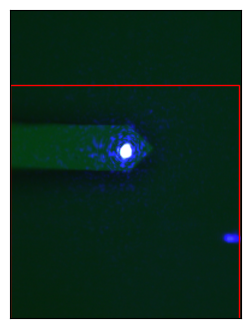

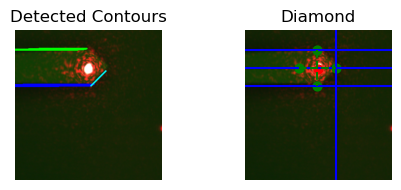

Calculated Position:
[0.05351776296148891, -0.07445788632732264]
Reasonable
---
Capturing Image:
   OVecPFM3197.tif


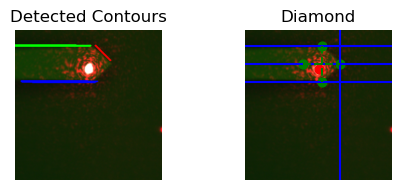

Calculated Position:
[-0.16651888890503896, -0.2871447782260306]
Reasonable
---
Capturing Image:
   OVecPFM3198.tif


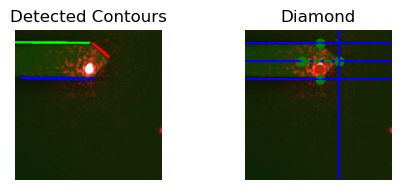

Calculated Position:
[-0.05239083209255746, -0.4490342086109398]
Reasonable
---
Capturing Image:
   OVecPFM3199.tif


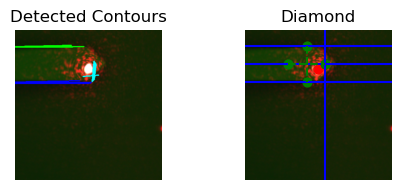

Calculated Position:
[0.6125739780586936, -0.27831257739666837]
Reasonable
---
Capturing Image:
   OVecPFM3200.tif


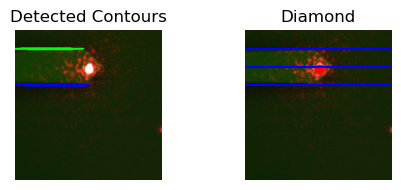

Calculated Position:
[nan, -0.10359219319196145]
Unreasonable
---
Capturing Image:
   OVecPFM3201.tif


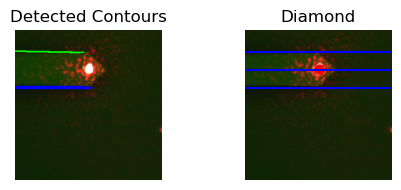

Calculated Position:
[nan, 0.06469079172922554]
Unreasonable
---
Capturing Image:
   OVecPFM3202.tif


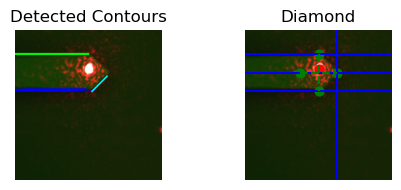

Calculated Position:
[0.013441946959896756, 0.19222922848664692]
Reasonable
---
Capturing Image:
   OVecPFM3203.tif


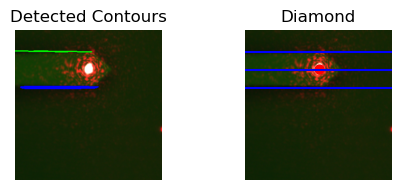

Calculated Position:
[nan, 0.04803279038490271]
Unreasonable
---
Capturing Image:
   OVecPFM3204.tif


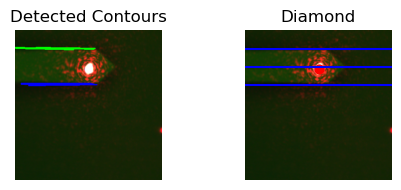

Calculated Position:
[nan, -0.12102489058710364]
Unreasonable
---
Capturing Image:
   OVecPFM3205.tif


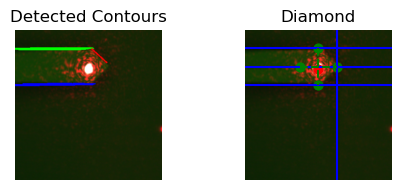

Calculated Position:
[0.019716172708615254, -0.1389527230539256]
Reasonable
Affine Transform:
[[ 3.33237678e+01 -8.70539965e-01]
 [ 1.65755280e+00  9.18174781e+01]
 [-1.36738168e+03  4.11585172e+02]]
Valid Diamonds:
6 out of 10


In [16]:
T = calculate_asylum_coordinate_to_lab_coordinate_transform(igor,
                                                             file_loc = file_loc,
                                                             base_filename = base_filename,
                                                             log_filename = log_filename,
                                                             box=[0,125,380,412],
                                                             verbose=True)

In [ ]:
T

In [17]:
 approach_coordinate(igor, T, [0,0], limit = 70, reps = 2)

In [ ]:
#approach_coordinate(igor, T, [0,0], limit = 70, reps = 4)

init_x = -0.6
final_x = 0.6
step_size = 0.2
number_of_steps = int(abs((final_x - init_x) / step_size))

for i in list(np.linspace(init_x, final_x, number_of_steps)):
    print(i)
    approach_coordinate(igor, T, [i,0], limit = 70, reps = 3)
    

In [ ]:
2861, -2042

In [ ]:
igor.Execute('td_wv("Red Laser", 1)')

In [ ]:
list(np.linspace(init_x, final_x, step_size))

In [ ]:
filename1 = 'Target'
filename2 = 'rubbish'

approach_coordinate(igor, T, [0,0], limit = 70, reps = 4)
T = calculate_asylum_coordinate_to_lab_coordinate_transform(igor,
                                                             file_loc = file_loc,
                                                             base_filename = base_filename,
                                                             log_filename = log_filename,
                                                             box=[0,100,380,312],
                                                             verbose=True)

approach_coordinate(igor, T, [0.8,0], limit = 70, reps = 4)
print('we reached the position!')
set_base_filename(igor, filename1)
igor.Execute('ARVideoButtonFunc("ARVCapture")')
set_base_filename(igor, filename2)
approach_coordinate(igor, T, [0,0], limit = 70, reps = 4)

T = calculate_asylum_coordinate_to_lab_coordinate_transform(igor,
                                                             file_loc = file_loc,
                                                             base_filename = base_filename,
                                                             log_filename = log_filename,
                                                             box=[0,100,380,312],
                                                             verbose=True)

approach_coordinate(igor, T, [-0.8,0], limit = 70, reps = 4)
print('we reached the position!')
set_base_filename(igor, filename1)
igor.Execute('ARVideoButtonFunc("ARVCapture")')
set_base_filename(igor, filename2)
approach_coordinate(igor, T, [0,0], limit = 70, reps = 4)

T = calculate_asylum_coordinate_to_lab_coordinate_transform(igor,
                                                             file_loc = file_loc,
                                                             base_filename = base_filename,
                                                             log_filename = log_filename,
                                                             box=[0,100,380,312],
                                                             verbose=True)

approach_coordinate(igor, T, [0.8,0], limit = 70, reps = 4)
print('we reached the position!')
set_base_filename(igor, filename1)
igor.Execute('ARVideoButtonFunc("ARVCapture")')
set_base_filename(igor, filename2)
approach_coordinate(igor, T, [0,0], limit = 70, reps = 4)

T = calculate_asylum_coordinate_to_lab_coordinate_transform(igor,
                                                             file_loc = file_loc,
                                                             base_filename = base_filename,
                                                             log_filename = log_filename,
                                                             box=[0,100,380,312],
                                                             verbose=True)

approach_coordinate(igor, T, [-0.8,0], limit = 70, reps = 4)
print('we reached the position!')
set_base_filename(igor, filename1)
igor.Execute('ARVideoButtonFunc("ARVCapture")')
set_base_filename(igor, filename2)
approach_coordinate(igor, T, [0,0], limit = 70, reps = 4)